In [1]:
from medmnist import PathMNIST
from torchvision import transforms

In [2]:
transform = transforms.Compose([
    transforms.Resize((100, 100)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


train = PathMNIST(split="train", transform=transform, download=False)
val   = PathMNIST(split="val",   transform=transform, download=False)
test  = PathMNIST(split="test",  transform=transform, download=False)

In [3]:
# Dataset info
print(f"Training samples: {len(train)}")
print(f"Validation samples: {len(val)}")
print(f"Test samples: {len(test)}")
print(f"Image shape: {train[0][0].shape}")
print(f"Number of classes: {len(train.info['label'])}")
print(f"Class labels: {train.info['label']}")

Training samples: 89996
Validation samples: 10004
Test samples: 7180
Image shape: torch.Size([3, 100, 100])
Number of classes: 9
Class labels: {'0': 'adipose', '1': 'background', '2': 'debris', '3': 'lymphocytes', '4': 'mucus', '5': 'smooth muscle', '6': 'normal colon mucosa', '7': 'cancer-associated stroma', '8': 'colorectal adenocarcinoma epithelium'}


In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import models
from tqdm import tqdm

# Configuration
BATCH_SIZE = 128
NUM_EPOCHS = 20
LEARNING_RATE = 0.001

# Use MPS (Metal Performance Shaders) for faster training on macOS
if torch.backends.mps.is_available():
    device = torch.device('mps')
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(train)

else:
    print("train is:")

    device = torch.device('cpu')

    print(f'Using device: {device}')

In [5]:
# Create combined training dataset
from torch.utils.data import ConcatDataset
full_train = ConcatDataset([train, val])

# Create data loaders
train_loader = DataLoader(full_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_loader = DataLoader(test, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f'Training batches: {len(train_loader)}')

# Create subset data loaders for faster training (25% of data)
from torch.utils.data import Subset
import numpy as np

x_train_indices = np.arange(0, int(len(train)/4))
x_val_indices = np.arange(0, int(len(val)/4))

x_train = Subset(train, x_train_indices)
x_val = Subset(val, x_val_indices)


x_train_loader = DataLoader(x_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
print(f'Reduced training batches: {len(x_train_loader)} (25% of data)')

x_val_loader = DataLoader(x_val, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

Training batches: 782
Reduced training batches: 176 (25% of data)


In [6]:
images, labels = next(iter(train_loader))
image = images[0]
print(image.shape)

torch.Size([3, 100, 100])


In [7]:
import torch.nn as nn
import torchvision.models as models

class AlexNetMedical(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.model = models.alexnet(pretrained=True)

        self.model.classifier[6] = nn.Linear(
            self.model.classifier[6].in_features,
            num_classes
        )

    def forward(self, x):
        return self.model(x)


In [8]:
# Initialize AlexNetMedical model
num_classes = len(train.info['label'])

medical_model = AlexNetMedical(num_classes=num_classes)
medical_model = medical_model.to(device)

print(f"AlexNetMedical loaded with {num_classes} output classes")


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


AlexNetMedical loaded with 9 output classes


In [9]:
# Loss function and optimizer for medical model
medical_criterion = nn.CrossEntropyLoss()
medical_optimizer = optim.SGD(
    medical_model.parameters(),
    lr=0.001,
    momentum=0.9,
    weight_decay=1e-4
)

In [10]:
# Training loop for AlexNetMedical
medical_history = {'train_loss': [], 'train_acc': []}
best_medical_val_acc = 0.0

for epoch in range(NUM_EPOCHS):
    print(f'\nEpoch {epoch+1}/{NUM_EPOCHS}')
    print('-' * 50)
    
    # Training phase
    medical_model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    
    for images, labels in tqdm(train_loader, desc='Training'):
        images = images.to(device)
        labels = labels.squeeze().long().to(device)
        
        medical_optimizer.zero_grad()
        outputs = medical_model(images)
        loss = medical_criterion(outputs, labels)
        loss.backward()
        medical_optimizer.step()
        
        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()
    
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = 100 * train_correct / train_total
    
    # Save history
    medical_history['train_loss'].append(epoch_train_loss)
    medical_history['train_acc'].append(epoch_train_acc)
    
    print(f'Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}%')

print(f'\nTraining complete!')


Epoch 1/20
--------------------------------------------------


Training: 100%|██████████| 782/782 [01:25<00:00,  9.10it/s]


Train Loss: 0.4468 | Train Acc: 83.89%

Epoch 2/20
--------------------------------------------------


Training: 100%|██████████| 782/782 [01:27<00:00,  8.92it/s]


Train Loss: 0.2655 | Train Acc: 90.58%

Epoch 3/20
--------------------------------------------------


...

Train Loss: 0.0538 | Train Acc: 98.03%

Epoch 19/20
--------------------------------------------------


Training: 100%|██████████| 782/782 [01:40<00:00,  7.77it/s]


Train Loss: 0.0488 | Train Acc: 98.23%

Epoch 20/20
--------------------------------------------------


Training: 100%|██████████| 782/782 [01:42<00:00,  7.63it/s]

Train Loss: 0.0468 | Train Acc: 98.33%

Training complete!


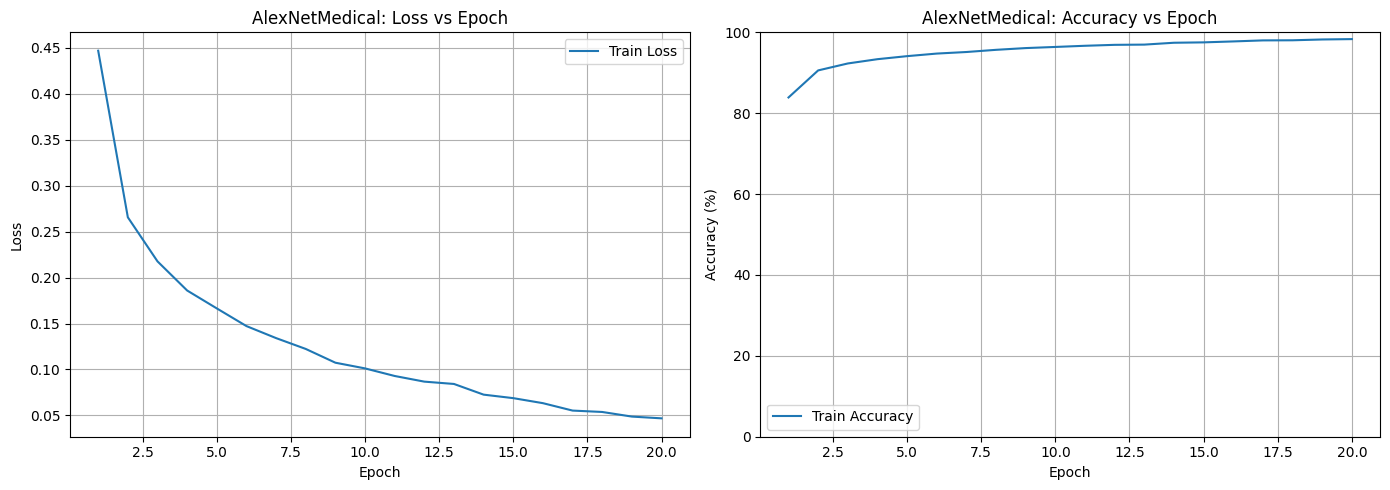

In [11]:
import matplotlib.pyplot as plt

epochs = range(1, len(medical_history['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ---- Loss plot ----
ax1.plot(epochs, medical_history['train_loss'], label='Train Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('AlexNetMedical: Loss vs Epoch')
ax1.legend()
ax1.grid(True)

# ---- Accuracy plot ----
ax2.plot(epochs, medical_history['train_acc'], label='Train Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_ylim(0, 100)
ax2.set_title('AlexNetMedical: Accuracy vs Epoch')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.savefig('alexnetmedical_training_curves.png', dpi=300)
plt.show()


In [12]:
# Evaluate ResNet18Medical on test set
medical_model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc='Testing AlexNetMedical'):
        images = images.to(device)
        labels = labels.squeeze().long().to(device)
        
        outputs = medical_model(images)
        _, predicted = torch.max(outputs, 1)
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_acc = 100 * test_correct / test_total
print(f'AlexNetMedical Test Accuracy: {test_acc:.2f}%')

Testing AlexNetMedical: 100%|██████████| 57/57 [00:14<00:00,  3.81it/s]

AlexNetMedical Test Accuracy: 89.22%


In [ ]:
# Save model with test accuracy in filename

model_filename = f"other/models/alexnet_full_{test_acc:.2f}_pathmnist.pth"
print(f"Model saved as {model_filename}")
torch.save(medical_model.state_dict(), model_filename)

Model saved as ../models/alexnet_full_89.22_pathmnist.pth


# Breast Cancer Dataset Training

In [15]:
# Load Breast Cancer Dataset
from torchvision.datasets import ImageFolder
from sklearn.model_selection import train_test_split
import os

# Define transforms for breast cancer dataset
bc_transform = transforms.Compose([
    transforms.Resize((100, 100)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load full dataset
data_dir = '../data'
full_bc_dataset = ImageFolder(root=data_dir, transform=bc_transform)

print(f"Total breast cancer images: {len(full_bc_dataset)}")
print(f"Classes: {full_bc_dataset.classes}")
print(f"Class to index mapping: {full_bc_dataset.class_to_idx}")

Total breast cancer images: 7909
Classes: ['benign', 'malignant']
Class to index mapping: {'benign': 0, 'malignant': 1}


In [16]:
# Split dataset into train, validation, and test sets
from torch.utils.data import Subset, ConcatDataset

# Get indices for each class
bc_indices = list(range(len(full_bc_dataset)))
bc_targets = [full_bc_dataset.targets[i] for i in bc_indices]

print(f"Total available images: {len(full_bc_dataset)}")

# Calculate split sizes based on available data
# Target: 7000 train, 1109 val, 1000 test if enough data
total_samples = len(full_bc_dataset)
if total_samples >= 9109:
    train_size = 7000
    val_size = 1109
    test_size = 1000
else:
    # Proportional split maintaining the ratios
    train_size = int(total_samples * 0.7684)  # 7000/9109
    val_size = int(total_samples * 0.1218)    # 1109/9109
    test_size = total_samples - train_size - val_size

print(f"Using split - Train: {train_size}, Val: {val_size}, Test: {test_size}")

# Split: First get training set
bc_train_indices, temp_indices = train_test_split(
    bc_indices, train_size=train_size, stratify=bc_targets, random_state=42
)

# Then split remaining into val and test
temp_targets = [bc_targets[i] for i in temp_indices]
remaining = len(temp_indices)
val_ratio = val_size / (val_size + test_size)
val_actual = int(remaining * val_ratio)

bc_val_indices, bc_test_indices = train_test_split(
    temp_indices, train_size=val_actual, stratify=temp_targets, random_state=42
)

# Create datasets
bc_train_dataset = Subset(full_bc_dataset, bc_train_indices)
bc_val_dataset = Subset(full_bc_dataset, bc_val_indices)
bc_test_dataset = Subset(full_bc_dataset, bc_test_indices)

# Don't use validation during training - only train and test
bc_full_train = bc_train_dataset

# Create data loaders
bc_train_loader = DataLoader(bc_full_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
bc_test_loader = DataLoader(bc_test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Training batches: {len(bc_train_loader)}")
print(f"Breast Cancer - Train: {len(bc_train_dataset)}, Val: {len(bc_val_dataset)}, Test: {len(bc_test_dataset)}")

Total available images: 7909
Using split - Train: 6077, Val: 963, Test: 869
Training batches: 48
Breast Cancer - Train: 6077, Val: 962, Test: 870


In [17]:
# Define AlexNet for Breast Cancer (2 classes)
class AlexNetBreastCancer(nn.Module):
    def __init__(self):
        super(AlexNetBreastCancer, self).__init__()
        # Load pretrained AlexNet
        self.model = models.alexnet(pretrained=True)
        
        # Modify the last layer for binary classification
        num_features = self.model.classifier[6].in_features
        self.model.classifier[6] = nn.Linear(num_features, 2)
    
    def forward(self, x):
        return self.model(x)

# Initialize model for breast cancer
bc_model = AlexNetBreastCancer().to(device)
print(f"AlexNet for Breast Cancer loaded and modified for 2 classes")
print(f"Model will be trained on: {device}")

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


AlexNet for Breast Cancer loaded and modified for 2 classes
Model will be trained on: mps


In [18]:
# Define loss and optimizer for breast cancer
bc_criterion = nn.CrossEntropyLoss()
bc_optimizer = optim.SGD(bc_model.parameters(), lr=LEARNING_RATE, momentum=0.9, weight_decay=1e-4)

print(f"Using SGD optimizer with lr={LEARNING_RATE}, momentum=0.9, weight_decay=1e-4")

Using SGD optimizer with lr=0.001, momentum=0.9, weight_decay=1e-4


In [19]:
# Training loop for breast cancer
bc_train_losses = []
bc_train_accuracies = []

print("Starting Breast Cancer training...")
for epoch in range(NUM_EPOCHS):
    bc_model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for inputs, labels in bc_train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        bc_optimizer.zero_grad()
        outputs = bc_model(inputs)
        loss = bc_criterion(outputs, labels)
        loss.backward()
        bc_optimizer.step()
        
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
    
    epoch_loss = running_loss / len(bc_train_loader)
    epoch_acc = 100. * correct / total
    bc_train_losses.append(epoch_loss)
    bc_train_accuracies.append(epoch_acc)
    
    print(f'Epoch [{epoch+1}/{NUM_EPOCHS}], Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.2f}%')

print("Breast Cancer training completed!")

Starting Breast Cancer training...
Epoch [1/20], Loss: 0.4711, Accuracy: 80.01%
Epoch [2/20], Loss: 0.3173, Accuracy: 87.30%
Epoch [3/20], Loss: 0.2785, Accuracy: 88.60%
Epoch [4/20], Loss: 0.2302, Accuracy: 90.57%
Epoch [5/20], Loss: 0.2012, Accuracy: 91.79%
Epoch [6/20], Loss: 0.1828, Accuracy: 92.50%
Epoch [7/20], Loss: 0.1651, Accuracy: 93.32%
Epoch [8/20], Loss: 0.1378, Accuracy: 94.36%
Epoch [9/20], Loss: 0.1343, Accuracy: 94.73%
Epoch [10/20], Loss: 0.1288, Accuracy: 94.67%
Epoch [11/20], Loss: 0.0945, Accuracy: 96.51%
Epoch [12/20], Loss: 0.1219, Accuracy: 95.21%
Epoch [13/20], Loss: 0.0824, Accuracy: 96.92%
Epoch [14/20], Loss: 0.0639, Accuracy: 97.66%
Epoch [15/20], Loss: 0.0579, Accuracy: 97.76%
Epoch [16/20], Loss: 0.0437, Accuracy: 98.57%
Epoch [17/20], Loss: 0.0529, Accuracy: 98.19%
Epoch [18/20], Loss: 0.0532, Accuracy: 97.93%
Epoch [19/20], Loss: 0.0388, Accuracy: 98.67%
Epoch [20/20], Loss: 0.0284, Accuracy: 99.19%
Breast Cancer training completed!


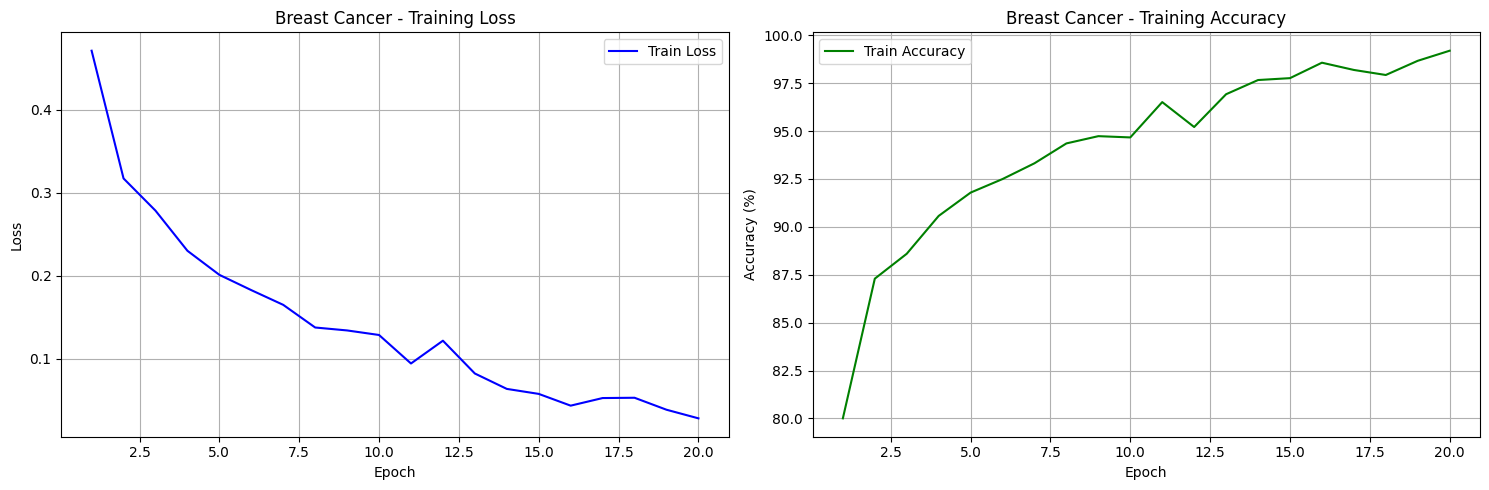

In [20]:
# Plot Breast Cancer training metrics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot training loss
ax1.plot(range(1, NUM_EPOCHS + 1), bc_train_losses, 'b-', label='Train Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Breast Cancer - Training Loss')
ax1.legend()
ax1.grid(True)

# Plot training accuracy
ax2.plot(range(1, NUM_EPOCHS + 1), bc_train_accuracies, 'g-', label='Train Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title('Breast Cancer - Training Accuracy')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

In [21]:
# Evaluate on Breast Cancer test set
bc_model.eval()
correct = 0
total = 0

with torch.no_grad():
    for inputs, labels in bc_test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = bc_model(inputs)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

bc_test_acc = 100. * correct / total
print(f'Breast Cancer Test Accuracy: {bc_test_acc:.2f}%')

Breast Cancer Test Accuracy: 92.87%


In [ ]:
# Save the breast cancer model
bc_model_path = f'other/models/alexnet_full_{bc_test_acc:.2f}_bc.pth'
torch.save(bc_model.state_dict(), bc_model_path)
print(f'Breast Cancer model saved to {bc_model_path}')

Breast Cancer model saved to ../models/alexnet_full_92.87_bc.pth
